# Checkpoint pipeline — QPINN and its classical controls

Two headline experiments, run from checkpoints so training never has to be
repeated just to change a plot:

1. **Parameter sweep** — fix architecture size `L`, sweep `(freq, alpha)` (heat)
   or `(freq, c)` (wave), heatmap of `rel_l2`.
2. **L sweep** — fix `(freq, alpha)`/`(freq, c)`, sweep `L`, line plot of
   `rel_l2` vs. `L`.

## Where the project stands

The original hypothesis was **spectral coverage**: the photonic layer's
probabilities are trigonometric polynomials whose frequency support $\Omega$
(the difference set of the Fock lattice, 471 vectors at the reference config)
is fixed by photon number and encoding depth, and that fixed high-frequency
support was supposed to explain the advantage over a spectrally-biased tanh
network.

**That hypothesis is falsified.** A classical control with *exactly* $\Omega$
and 6.5x the parameters fails completely; so does one that keeps the
modulus-squared structure with free complex amplitudes at 8.8x the parameters.
The transplant diagnostic then showed the quantum arm's trained solution lies
*inside* that failing model's function class (agreement to 1e-6), so the
failure cannot be representational. Constraining the amplitude matrix to
factor through a **unitary** is the single change that turns total failure
into success.

**Current claim:** the photonic layer is a structured unitary feature map, and
its advantage over a parameter-matched classical PINN is an *optimisation*
effect, not a representational one. The mechanism is entirely classical.

## The arms

| `model_type` | middle block | params (F=4, L=1) |
|---|---|---|
| `classical` | dense tanh block, param-matched | 310 |
| `quantum` | photonic layer (MerLin) | 310 |
| `fourier_features` | fixed axis-aligned frequencies, linear coeffs | ~350 |
| `fourier_full` | fixed full $\Omega$, linear coeffs | ~2010 |
| `fourier_modulus` | sparse comb + $|\cdot|^2$, free complex $M$ | 2720 |
| `fourier_unitary` | $M = B\,\mathrm{diag}(A)$, $B$ orthogonal (Cayley/Givens) | ~935 |
| `fourier_symmetric` | symmetric power of two $m\times m$ mode unitaries | 320 |

## How the checkpoint mechanism works

- Every `(pde params, L, model_type, seed)` run is trained once and saved as its
  own file under `checkpoints/<experiment>/`, containing everything needed to
  replot it: weights, loss history, evaluation grid, metrics, diagnostics.
- Re-running a run cell with the SAME config **skips** anything already on
  disk. Only genuinely new runs train.
- Every arm has its own `model_type`, so filenames never collide — new controls
  are added alongside existing checkpoints without touching them.
- **`ARMS_TO_TRAIN` (next cell) controls which arms the run cells train.** Set
  it to just the new arm to overlay a curve without retraining the expensive
  `quantum` runs. Plot cells always load *everything* on disk regardless.
- All plot cells only ever `load_checkpoints(...)` — they never retrain.

In [26]:
%load_ext autoreload
%autoreload 2

import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # running from notebooks/
sys.path.insert(0, str(ROOT))

import torch
from src.pde import HeatEquation, WaveEquation
from src.checkpoints import (
    run_param_sweep_checkpoints, run_L_sweep_checkpoints, resume_checkpoint,
    load_checkpoint, load_checkpoints, checkpoints_to_dataframe, resolve_matched_config,
    run_param_sweep_ff_checkpoints, run_L_sweep_ff_checkpoints,
    transplant_diagnostic,
)
from src.checkpoint_plots import (
    plot_param_sweep_heatmap, plot_L_sweep,
    plot_checkpoint_training_curve, plot_checkpoint_solution, plot_checkpoint_spectrum,
    plot_effective_bandwidth_vs_L,
    plot_ff_control_heatmap, plot_L_sweep_with_ff, plot_freq_sweep_lines
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Matching-search results are cached here so re-running a cell never repeats
# the brute-force parameter search.
MATCH_CACHE = {}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu


## Shared config

`ARMS_TO_TRAIN` is the only knob you need to touch to add a new curve to
existing results. Everything already on disk is reused; anything not listed
here is simply not trained this session.

In [ ]:
FEATURE_SIZE = 4          # quantum input modes - 1
HIDDEN_FEATURE = 16       # feature_map hidden width
HIDDEN_READOUT_QUANTUM = 4  # quantum model's readout hidden width

PDE_TYPE = "heat"         # "heat" | "wave"

EPOCHS = 15000
TRACK_BEST = True         # evaluate on a fixed grid periodically, keep the best checkpoint
EVAL_EVERY = 200
SEEDS = [67]#[42, 666, 69, 67]        #[42, 666, 69, 67]

# ---- which arms to TRAIN this session -------------------------------------
# Anything already on disk is skipped, so leaving an arm in here is cheap --
# but removing it guarantees it is never retrained (useful for `quantum`,
# which is slow). Plot cells ignore this and show everything found on disk.
#
#   "classical", "quantum",                      <- the two original arms
#   "fourier_features", "fourier_full",          <- spectral-coverage controls
#   "fourier_modulus", "fourier_unitary",        <- amplitude-structure controls
#   "fourier_symmetric"                          <- symmetric-power reimplementation
#ARMS_TO_TRAIN = ["fourier_symmetric"]
ARMS_TO_TRAIN = ["fourier_unitary"]

BASE_ARMS = [a for a in ARMS_TO_TRAIN if a in ("classical", "quantum")]
CONTROL_ARMS = [a for a in ARMS_TO_TRAIN if a.startswith("fourier_")]
print("base arms   :", BASE_ARMS or "(none — existing checkpoints reused)")
print("control arms:", CONTROL_ARMS or "(none)")

base arms   : (none — existing checkpoints reused)
control arms: ['fourier_unitary']


---
## Experiment 1 — parameter sweep at fixed L

Sweep `(freq, alpha)` (heat) / `(freq, c)` (wave) at a fixed architecture size
`L`, for every seed in `SEEDS`.

In [65]:
L_PARAM_SWEEP = 1

FREQ_VALUES = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0]
#FREQ_VALUES = [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5]
#FREQ_VALUES = [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
ALPHA_OR_C_VALUES = [0.001]   # alpha for heat, c for wave
PARAM2_NAME = "alpha" if PDE_TYPE == "heat" else "c"

PARAM_SWEEP_DIR = ROOT / "checkpoints" / "param_sweep"

In [66]:
# Trains only whatever isn't already on disk AND is listed in ARMS_TO_TRAIN.
sweep_kwargs = dict(
    ckpt_dir=PARAM_SWEEP_DIR,
    pde_type=PDE_TYPE,
    param1_name="freq", param1_values=FREQ_VALUES,
    param2_name=PARAM2_NAME, param2_values=ALPHA_OR_C_VALUES,
    L=L_PARAM_SWEEP,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)

if BASE_ARMS:
    run_param_sweep_checkpoints(model_types=BASE_ARMS, **sweep_kwargs)

for mt in CONTROL_ARMS:
    print(f"\n=== experiment 1 :: {mt} ===")
    run_param_sweep_ff_checkpoints(model_type=mt, **sweep_kwargs)


=== experiment 1 :: fourier_unitary ===
Parameters — total: 935  trainable: 935

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.5889e+00 | PDE: 7.13e-08 | Cons: 2.51e-01 | IC: 4.93e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.0035e+00
  MAE         : 6.2503e-01
  Max abs err : 1.0029e+00
  RMSE        : 7.0022e-01
Epoch    50/15000 | Loss: 7.5666e-01 | PDE: 1.40e-01 | Cons: 4.49e-01 | IC: 7.84e-02 | BC: 0.00e+00 | Time: 0.3s
Epoch   100/15000 | Loss: 5.8843e-01 | PDE: 1.16e-01 | Cons: 4.23e-01 | IC: 5.21e-02 | BC: 0.00e+00 | Time: 0.6s
Epoch   150/15000 | Loss: 1.2371e-01 | PDE: 3.00e-02 | Cons: 8.22e-02 | IC: 1.05e-02 | BC: 0.00e+00 | Time: 0.9s
Epoch   200/15000 | Loss: 2.4875e-02 | PDE: 5.55e-03 | Cons: 1.37e-02 | IC: 2.49e-03 | BC: 0.00e+00 | Time: 1.1s
Evaluating on 60×60 grid …
  Relative L2 : 1.1634e-01
  MAE         : 7.2072e-02
  Max abs err : 1.2794e-01
  RMSE        : 8.1174e-02
Epoch   250/15000 | Loss: 3

420 checkpoints loaded
['classical', 'fourier_full', 'fourier_symmetric', 'fourier_unitary', 'quantum']
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/param_sweep_heatmap.png


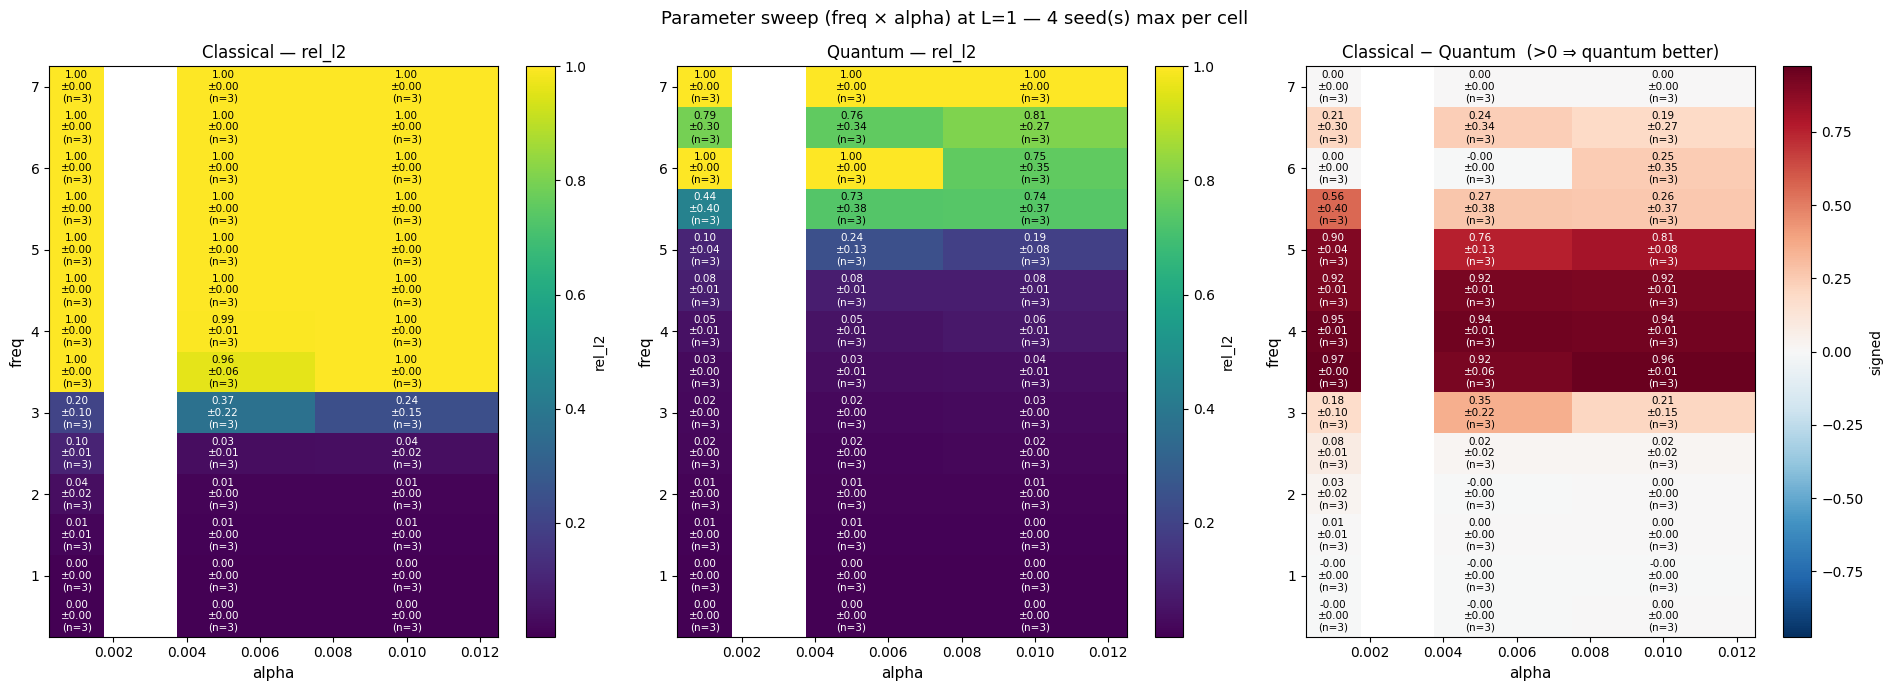

In [67]:
# Plot cells read from disk only -- they show every arm present, regardless of
# what was trained this session.
param_sweep_ckpts = load_checkpoints(PARAM_SWEEP_DIR, pde_type=PDE_TYPE, L=L_PARAM_SWEEP)
print(f"{len(param_sweep_ckpts)} checkpoints loaded")
print(sorted(set(c['config']['model_type'] for c in param_sweep_ckpts)))

fig = plot_param_sweep_heatmap(
    param_sweep_ckpts, param1_name="freq", param2_name=PARAM2_NAME,
    metric="rel_l2", save_path=ROOT / "figures" / "checkpoint_pipeline" / "param_sweep_heatmap.png",
)

Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/ff_control_heatmap.png


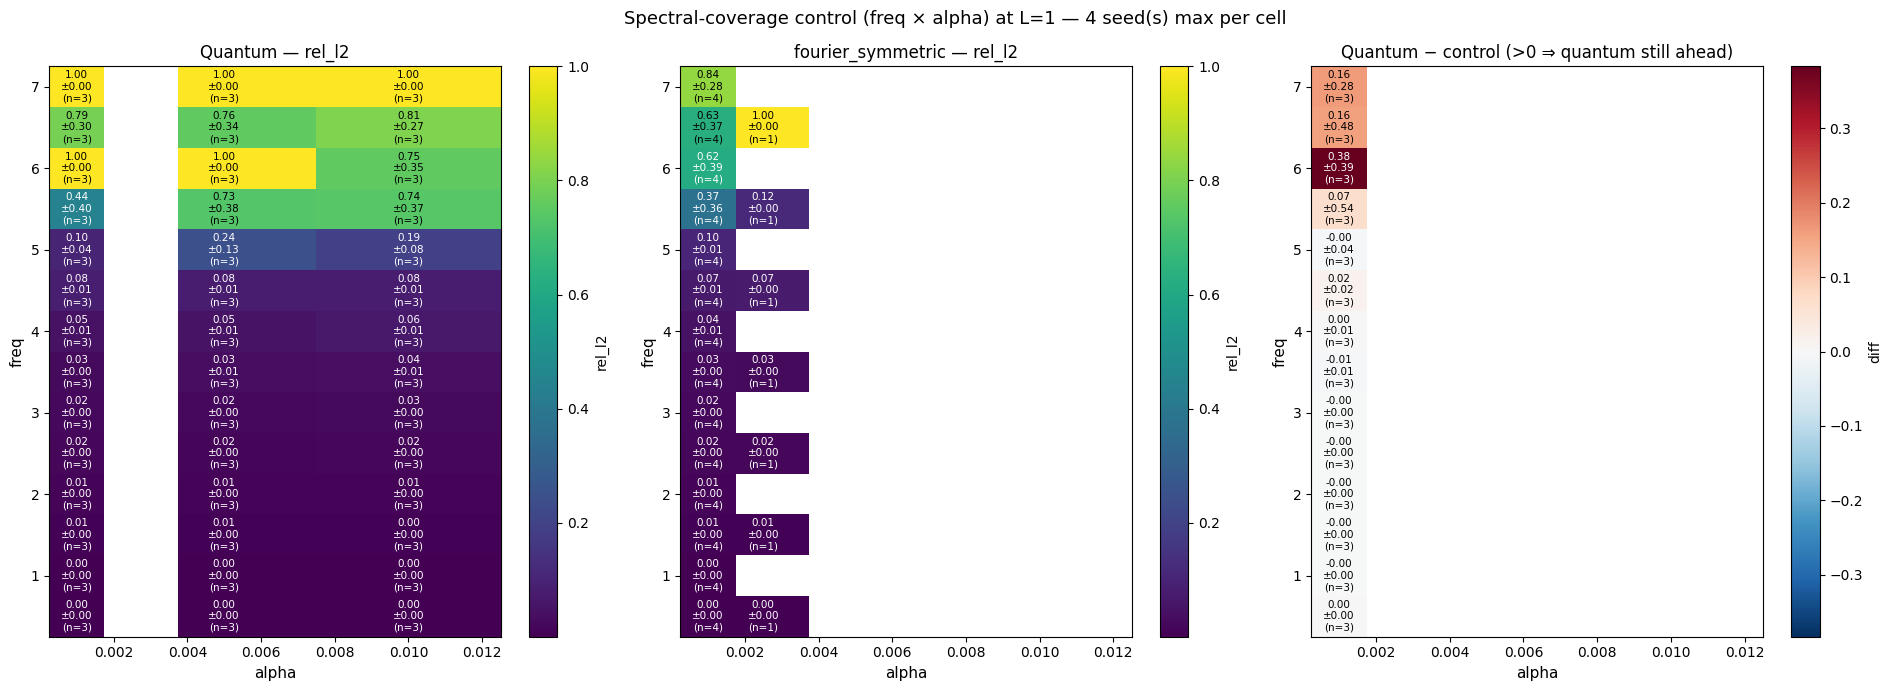

Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/freq_sweep_lines.png


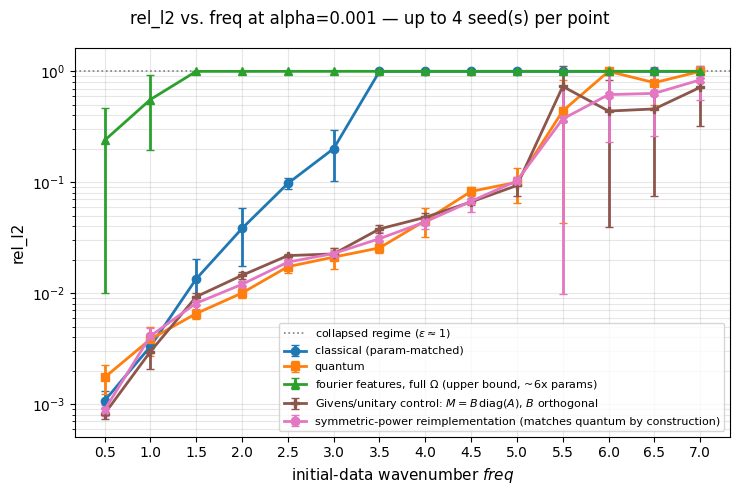

In [68]:
# Quantum vs. one control, side by side. Switch `control_model_type` to any
# fourier_* arm present on disk.
fig = plot_ff_control_heatmap(
    param_sweep_ckpts, param1_name="freq", param2_name=PARAM2_NAME,
    metric="rel_l2", control_model_type="fourier_symmetric",            #fourier_unitary, fourier_symmetric
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "ff_control_heatmap.png",
)

fig = plot_freq_sweep_lines(
    param_sweep_ckpts,
    param2_name=PARAM2_NAME,
    param2_value=ALPHA_OR_C_VALUES[0],
    metric="rel_l2",
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "freq_sweep_lines.png",
)

In [ ]:
checkpoints_to_dataframe(param_sweep_ckpts).sort_values(
    ["freq", PARAM2_NAME, "model_type", "seed"]
)

---
## Experiment 2 — L sweep at fixed PDE parameters

Fix `(freq, alpha)`/`(freq, c)`, sweep architecture size `L`, for every seed in
`SEEDS`. This is where the depth-dependence of the frequency ceiling shows up.

In [5]:
DEPTHS = [1, 2, 3, 4]

FIXED_FREQ = 7.0
FIXED_ALPHA_OR_C = 0.0025

if PDE_TYPE == "heat":
    L_SWEEP_PDE = HeatEquation(freq=FIXED_FREQ, alpha=FIXED_ALPHA_OR_C)
else:
    L_SWEEP_PDE = WaveEquation(freq=FIXED_FREQ, c=FIXED_ALPHA_OR_C)

L_SWEEP_DIR = ROOT / "checkpoints" / "L_sweep"

In [8]:
L_kwargs = dict(
    ckpt_dir=L_SWEEP_DIR,
    pde=L_SWEEP_PDE,
    depths=DEPTHS,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)

if BASE_ARMS:
    run_L_sweep_checkpoints(model_types=BASE_ARMS, **L_kwargs)

for mt in CONTROL_ARMS:
    print(f"\n=== experiment 2 :: {mt} ===")
    run_L_sweep_ff_checkpoints(model_type=mt, **L_kwargs)


=== experiment 2 :: fourier_symmetric ===
[checkpoints] skip (already exists): heat__alpha0p0025_freq7__L1__fs4_hf16_hr4_qos35__fourier_symmetric__seed42__ep15000.pt
  [   1/16] L=1 seed=42 fourier_features elapsed=0.0m eta=0.0m
Parameters — total: 320  trainable: 320

Training for 15000 epochs on cpu  (dtype=torch.float32)
Epoch     1/15000 | Loss: 2.6035e+00 | PDE: 4.23e-06 | Cons: 6.97e-02 | IC: 5.14e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 1.0030e+00
  MAE         : 1.3448e-01
  Max abs err : 1.0213e+00
  RMSE        : 2.3349e-01
Epoch    50/15000 | Loss: 2.8347e+00 | PDE: 7.78e-07 | Cons: 2.94e-03 | IC: 5.67e-01 | BC: 0.00e+00 | Time: 0.9s
Epoch   100/15000 | Loss: 2.2330e+00 | PDE: 7.17e-07 | Cons: 9.96e-04 | IC: 4.46e-01 | BC: 0.00e+00 | Time: 1.6s


KeyboardInterrupt: 

In [ ]:
L_sweep_ckpts = load_checkpoints(
    L_SWEEP_DIR, pde_type=PDE_TYPE, freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)
print(f"{len(L_sweep_ckpts)} checkpoints loaded")
print(sorted(set(c['config']['model_type'] for c in L_sweep_ckpts)))

In [ ]:
# Original two-arm view (classical vs. quantum only).
# target_frequency: the PDE's integer spatial mode (2*freq for the heat
# convention used here) -- marks the predicted plateau (L * n_photons >= target).
fig = plot_L_sweep(
    L_sweep_ckpts, metric="rel_l2", target_frequency=2 * FIXED_FREQ,
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "L_sweep.png",
)

In [ ]:
# All arms present on disk, overlaid. This is the headline figure: absent arms
# are skipped silently, so it works however many controls you have run.
fig = plot_L_sweep_with_ff(
    L_sweep_ckpts, metric="rel_l2", target_frequency=2 * FIXED_FREQ,
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "L_sweep_with_controls.png",
)

In [ ]:
# Compact comparison: mean rel_l2 and parameter count per arm per L.
df_L = checkpoints_to_dataframe(L_sweep_ckpts)
display(df_L.pivot_table(index="L", columns="model_type", values="rel_l2", aggfunc="mean"))
display(df_L.pivot_table(index="L", columns="model_type", values="param_count", aggfunc="first"))

---
## Transplant diagnostic — representational or optimisational?

At `L=1` the `fourier_modulus` arm strictly **contains** the quantum model's
function class: setting $M = B\,\mathrm{diag}(A)$ reproduces it exactly, so the
quantum arm is the subset where $M$ factors through a unitary.

This cell recovers $M$ from a trained quantum checkpoint by inverse DFT (exact,
no aliasing, since every frequency component lies in $\{0..N\}$ and the grid has
$N+1$ points per axis), transplants it, and evaluates both.

A **match** means the trained solution is reachable by the free-$M$ classical
model but is never *found* from random init — i.e. the quantum arm's advantage
is optimisation, not capacity. Check `reconstruction_error` and
`u_discrepancy` are both <= ~1e-4 before believing the comparison.

In [ ]:
qckpt = load_checkpoints(
    L_SWEEP_DIR, model_type="quantum", L=1,
    freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)[0]
info = transplant_diagnostic(qckpt, device=DEVICE)

---
## Per-checkpoint plots — training curve, spectral content, solution

Pick any single run from either experiment and inspect it directly, with no
retraining. `plot_checkpoint_spectrum` applies to `quantum` checkpoints only.

In [ ]:
# Example: the quantum run with the largest error in the L sweep -- swap in any
# (dir, filters) you want to look at.
df = checkpoints_to_dataframe(L_sweep_ckpts)
worst = df[df.model_type == "quantum"].sort_values("rel_l2", ascending=False).iloc[0]
print(worst)

ckpt = load_checkpoints(
    L_SWEEP_DIR, model_type="quantum", L=int(worst.L), seed=int(worst.seed),
    freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)[0]

In [ ]:
_ = plot_checkpoint_training_curve(ckpt, component="total")

In [ ]:
_ = plot_checkpoint_solution(ckpt)

In [ ]:
_ = plot_checkpoint_spectrum(ckpt)  # quantum-only

---
## Spectral bandwidth vs. encoding depth

Reduces every QUANTUM checkpoint's quantum-layer spectrum to a single scalar
per run, plotted against `L`, mean ± std over the seeds present. The dashed
line is the analytic ceiling $\Omega = L\,N$ from each checkpoint's stored
`analytic_bound`.

Swap `metric` for `"spectral_second_moment"` (energy-weighted RMS, no
threshold) or `"fraction_of_ceiling_used"` (bounded in [0,1], comparable across
`L`) — see `src/checkpoint_plots.py::_SPECTRUM_METRICS`.

In [ ]:
fig, bandwidth_df = plot_effective_bandwidth_vs_L(
    L_sweep_ckpts, metric="effective_bandwidth",
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "effective_bandwidth_vs_L.png",
)
bandwidth_df.sort_values(["L", "seed"])

---
## Resuming — continue training an existing checkpoint

`resume_checkpoint` takes any checkpoint, trains it for more epochs, and saves
the result as a NEW file (same config, `epochs` bumped, plus a
`resumed_from_epochs` field) — the original is untouched. This is a lightweight
resume (fresh optimizer state, reseeded sampling for the extra epochs), not
bit-exact continuation.

Useful when a run is still descending at the epoch budget rather than
plateaued — check the training curve above before concluding an arm has
converged.

In [ ]:
print(f"before resume: epochs={ckpt['config']['epochs']}  rel_l2={ckpt['metrics']['rel_l2']:.3e}")

resumed_path = resume_checkpoint(
    ckpt_dir=L_SWEEP_DIR,
    source=ckpt,
    additional_epochs=200,
    device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
)
resumed_ckpt = load_checkpoint(resumed_path)

print(f"after resume:  epochs={resumed_ckpt['config']['epochs']}  rel_l2={resumed_ckpt['metrics']['rel_l2']:.3e}")
assert resumed_ckpt["config"]["epochs"] == ckpt["config"]["epochs"] + 200
assert len(resumed_ckpt["history"]) == len(ckpt["history"]) + 200
print("OK -- resumed checkpoint has the expected epoch count and history length")

In [ ]:
_ = plot_checkpoint_training_curve(resumed_ckpt, component="total")